# Per-structure variants (docs/variant_registry.md) x balancing modes

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
DATASETS = json.loads((ROOT / "configs" / "chosen_datasets.json").read_text())["variants"]
RUN = False
if RUN:
    import subprocess
    subprocess.run([sys.executable, "-m", "experiments.sweep", "--phase", "variants", "--datasets", *DATASETS, "--workers", "2"])

balance,lb,none,warmup
variant,,,
default,0.651,0.441,0.471
hash,NaN,0.246,NaN
top1,0.604,0.582,0.591


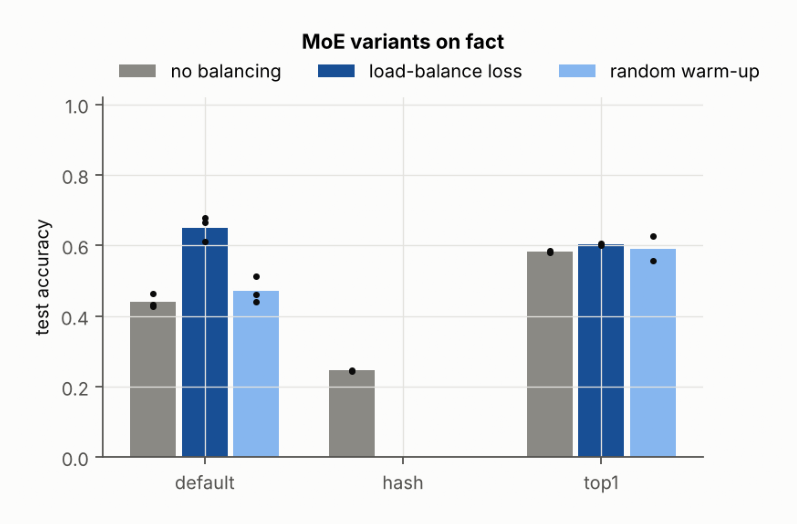

balance,lb,none,warmup
variant,,,
default,0.456,0.520,0.430
k6,0.658,0.665,0.690
shared2,0.353,0.372,0.296


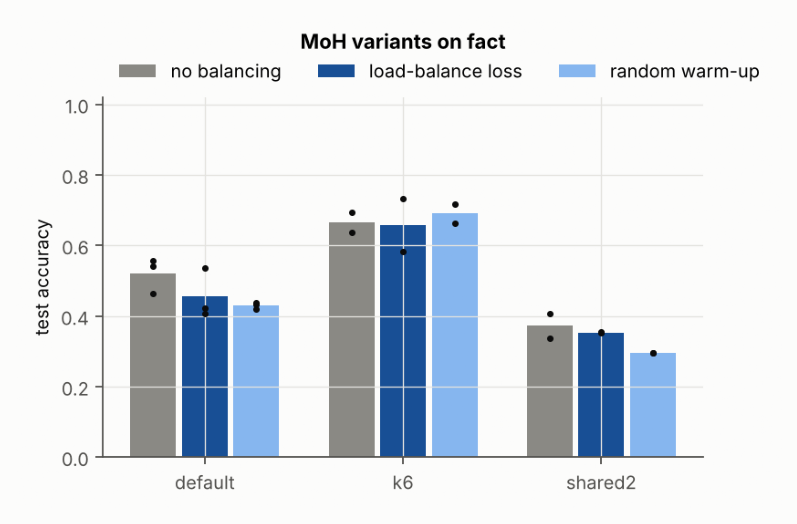

balance,lb,none,warmup
variant,,,
default,0.457,0.352,0.405
k8,0.789,0.783,0.785
renorm_detached,0.204,0.207,0.174


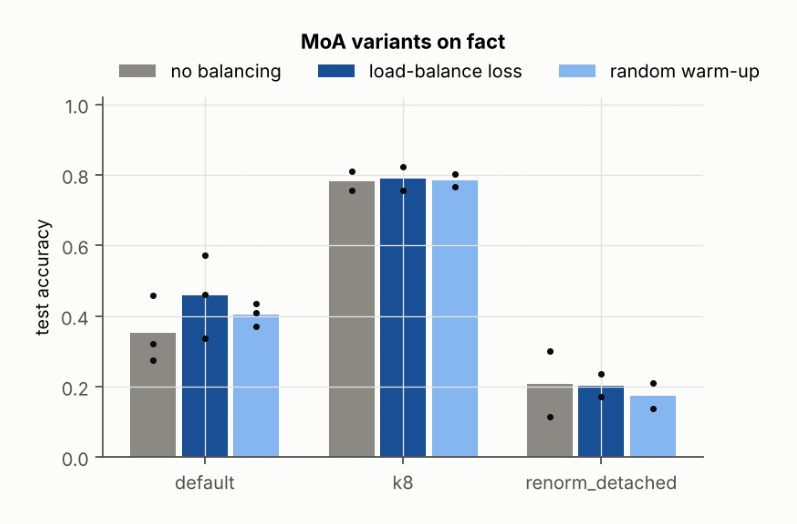

balance,lb,none,warmup
variant,,,
default,0.338,0.453,0.420
top1,0.124,0.053,0.139


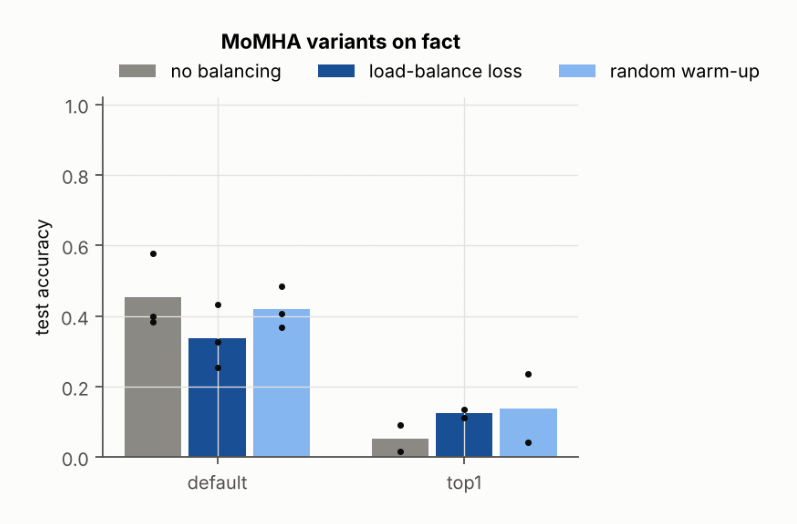

balance,lb,none,warmup
variant,,,
default,0.013,0.009,0.009
gru,0.021,0.010,0.009
k2,0.083,0.175,0.064
noskip,0.010,0.070,0.030


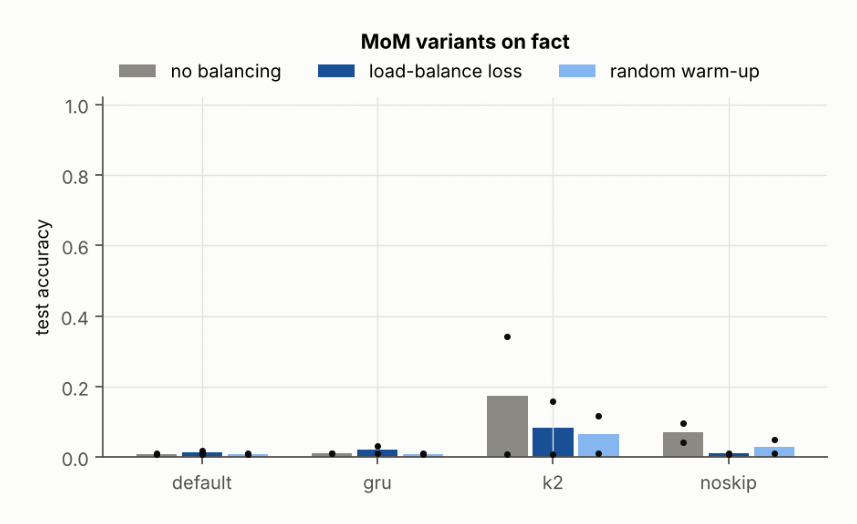

balance,lb,none,warmup
variant,,,
default,0.213,0.222,0.214
m16k16,0.438,0.440,0.457
m4k4,0.056,0.079,0.075
noshared,0.092,0.092,0.112
s2,0.222,0.232,0.228


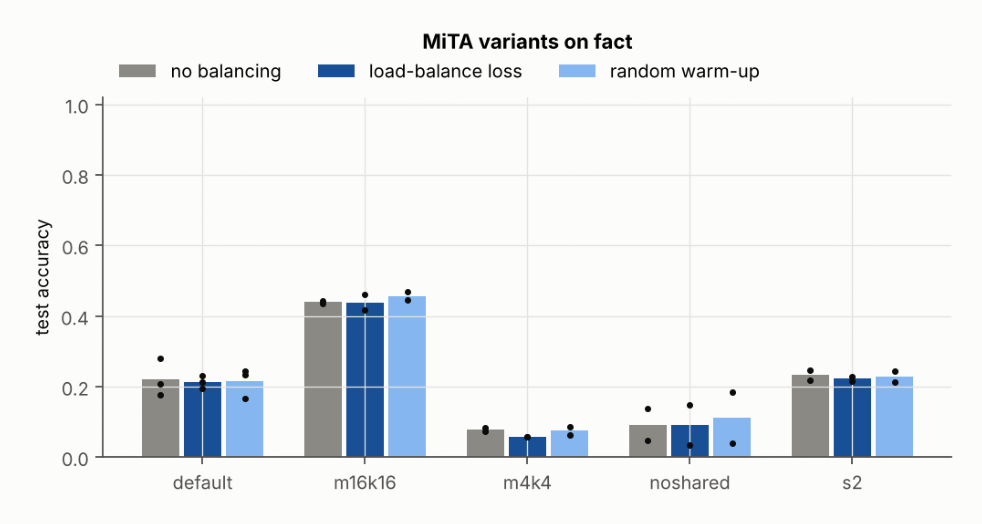

In [3]:
from analysis.collect import load_results, agg
from analysis import figures as F
import matplotlib.pyplot as plt, matplotlib.image as mpimg
df = load_results(RUNS_ROOT)
for d in DATASETS:
    for s in ["moe", "moh", "moa", "momha", "mom", "mita"]:
        t = agg(df[(df.dataset == d) & (df.structure == s)], ["variant", "balance"])
        display(t.pivot(index="variant", columns="balance", values="mean").round(3))
        p = F.variants_bars(df, d, s); plt.figure(figsize=(9, 4)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()